# Build a Simple RAG System

#### Install OpenAI, and LangChain dependencies

In [9]:
#!pip install langchain==0.3.10

In [10]:
#!pip install langchain-openai==0.2.12

In [11]:
#!pip install langchain-community==0.3.11

In [12]:
#!pip install dill

In [13]:
#!pip install langchain-chroma==0.1.4

In [14]:
#!pip install ragas==0.3.7

In [15]:
#!pip install deepeval==3.6.8

In [16]:
# Enter OpenAI API Key

from getpass import getpass
OPENAI_API_KEY = getpass("Enter your OpenAI API Key here: ")

Enter your OpenAI API Key here: ··········


In [17]:
import os
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

In [18]:
# Open AI Embedding Models
from langchain_openai import OpenAIEmbeddings
openai_embed_model = OpenAIEmbeddings(model="text-embedding-3-small")

# Loading and Processing the Data

In [19]:
# if you can't download using the following code
# go to https://drive.google.com/file/d/1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb/view?usp=sharing download it
# manually upload it on colab
!gdown 1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb

Downloading...
From: https://drive.google.com/uc?id=1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb
To: /content/rag_eval_docs.csv
100% 2.66k/2.66k [00:00<00:00, 13.9MB/s]


## Load and Process the dataset

In [20]:
import pandas as pd
df = pd.read_csv('/content/rag_eval_docs.csv')
df

,id,title,context
0,1,Machine Learning,Machine learning is a field of artificial inte...
1,2,Deep Learning,Deep learning is a subset of machine learning ...
2,3,Natural Language Processing (NLP),NLP is a branch of AI that enables computers t...
3,4,Pyramids,"Pyramids are ancient structures, often serving..."
4,5,Photosynthesis,Photosynthesis is the process plants use to co...
5,6,Biology,"Biology is the study of living organisms, cove..."
6,7,Quantum Mechanics,Quantum mechanics is a branch of physics that ...
7,8,Cryptocurrency,Cryptocurrency is a digital currency that uses...
8,9,Renewable Energy,"Renewable energy sources, such as solar and wi..."
9,10,Artificial Intelligence,Artificial intelligence refers to machines mim...


In [21]:
docs = df.to_dict(orient='records')
docs[:3]

[{'id': 1,
  'title': 'Machine Learning',
  'context': 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.'},
 {'id': 2,
  'title': 'Deep Learning',
  'context': 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.'},
 {'id': 3,
  'title': 'Natural Language Processing (NLP)',
  'context': 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'}]

In [22]:
from langchain.docstore.document import Document
processed_docs = []

for doc in docs:
  metadata = {
      "title": doc['title'],
      "id": doc['id']
  }
  data = doc['context']
  processed_docs.append(Document(page_content=data, metadata=metadata))
processed_docs[:3]

[Document(metadata={'title': 'Machine Learning', 'id': 1}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.'),
 Document(metadata={'title': 'Deep Learning', 'id': 2}, page_content='Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.'),
 Document(metadata={'title': 'Natural Language Processing (NLP)', 'id': 3}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.')]

In [23]:
# Index Document Chunking and Embeddings in VectorDB (ChromaDB)
# NOTE - please execute only one time otherwise it can create duplicate metadata and page_context and
# whenever you retrieve user query from vector database, the duplicate data come first and that will impact your model
# performance.
from langchain_chroma import Chroma
chroma_db = Chroma.from_documents(documents=processed_docs,
                                  collection_name='my_db',embedding=openai_embed_model,
                                  collection_metadata={"hnsw:space": "cosine"},
                                  persist_directory='./my_db')


ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


In [24]:
# Load Vector DB from disk

from langchain_chroma import Chroma
chroma_db = Chroma(persist_directory='./my_db', collection_name='my_db',
                   embedding_function=openai_embed_model)

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


# Semantic Similarity Based Retrieval

In [25]:
# Retrieval part
similarity_retriever = chroma_db.as_retriever(search_type='similarity_score_threshold',
                                              search_kwargs={"k": 5, "score_threshold":0.3})

In [26]:
from IPython.display import display, Markdown
def display_docs(docs):
  for doc in docs:
    print("Metadata: ", doc.metadata)
    print("Content Brief: ")
    display(Markdown(doc.page_content))
    print()

In [27]:
query = "What is AI?"
top_docs = similarity_retriever.invoke(query)
display_docs(top_docs)

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


Metadata:  {'id': 10, 'title': 'Artificial Intelligence'}
Content Brief: 


Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.


Metadata:  {'id': 3, 'title': 'Natural Language Processing (NLP)'}
Content Brief: 


NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.


Metadata:  {'id': 1, 'title': 'Machine Learning'}
Content Brief: 


Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.


Metadata:  {'id': 2, 'title': 'Deep Learning'}
Content Brief: 


Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.

In [28]:
query = "How do plants survive?"
top_docs = similarity_retriever.invoke(query)
display_docs(top_docs)

Metadata:  {'id': 5, 'title': 'Photosynthesis'}
Content Brief: 


Photosynthesis is the process plants use to convert sunlight into energy. This process produces glucose and releases oxygen as a byproduct. It is crucial for sustaining life on Earth by providing food and oxygen.

# Build the RAG Pipeline

In [29]:
# Augmentation part
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = """You are an assistant who is an expert in question-answering tasks.
              Answer the following question using only the following pieces of retrieved context.
              If the answer is not in the context, do not make up answers, just say that
              you don't know. Keep the answer to the point based on the information from the context.

              Question:
              {question}

              Context:
              {context}

              Answer:
              """
rag_prompt_template = ChatPromptTemplate.from_template(rag_prompt)

In [30]:
# LLM model (Langchain model for building RAG System)
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import OpenAI
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_core.runnables import RunnableLambda
from operator import itemgetter

In [31]:
from langchain_openai import ChatOpenAI
chatgpt = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)
def format_docs(docs):
  return "\n\n".join(doc.page_content for doc in docs)

src_rag_response_chain = (
    {
        "context": (itemgetter("context") | RunnableLambda(format_docs)),
        "question": RunnablePassthrough(),
    }
    | rag_prompt_template
    | chatgpt
    | StrOutputParser()
)


rag_chain_w_sources = (
    {"context": similarity_retriever, "question": RunnablePassthrough()}
    | RunnablePassthrough.assign(response = src_rag_response_chain))

In [32]:
query = "How do plants survive?"
result = rag_chain_w_sources.invoke(query)
result

{'context': [Document(metadata={'id': 5, 'title': 'Photosynthesis'}, page_content='Photosynthesis is the process plants use to convert sunlight into energy. This process produces glucose and releases oxygen as a byproduct. It is crucial for sustaining life on Earth by providing food and oxygen.')],
 'question': 'How do plants survive?',
 'response': 'Plants survive by using photosynthesis to convert sunlight into energy, producing glucose and releasing oxygen, which is essential for sustaining life on Earth.'}

In [33]:
query = "What is AI?"
result = rag_chain_w_sources.invoke(query)
result

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

# Create a Synthetic RAG Golden Reference Dataset

In [34]:
doc_contexts = [doc.page_content for doc in processed_docs]
doc_contexts[:3]

['Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.',
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.']

In [35]:
#!pip install deepeval==3.6.8

In [36]:
#from deepeval.synthesizer import Synthesizer
#from deepeval.synthesizer import types

In [37]:
"""
synthesizer = Synthesizer(model ="gpt-4o")
eval_data = synthesizer.generate_goldens(
    # Provide a list of context for synthatic data generation
    documents = [[doc] for doc in doc_contexts],
    include_expected_output=True,
    max_goldens_per_context=1,
    num_evolutions=1,
    scenario="Retrieval Augmented Generation",
    task="Question Answering",
    evolutions = {
        "reasoning": 0.1,
        "multicontext": 0.9,
        "concretizing": 0.9,
        "constrained": 0.0,
        "comparative":0.0,
        "hypothetical": 0.0,
        "in_breadth": 0.0,
    }
)
"""

'\nsynthesizer = Synthesizer(model ="gpt-4o")\neval_data = synthesizer.generate_goldens(\n    # Provide a list of context for synthatic data generation\n    documents = [[doc] for doc in doc_contexts],\n    include_expected_output=True,\n    max_goldens_per_context=1,\n    num_evolutions=1,\n    scenario="Retrieval Augmented Generation",\n    task="Question Answering",\n    evolutions = {\n        "reasoning": 0.1,\n        "multicontext": 0.9,\n        "concretizing": 0.9,\n        "constrained": 0.0,\n        "comparative":0.0,\n        "hypothetical": 0.0,\n        "in_breadth": 0.0,\n    }\n)\n'

# Evaluation Metrics

### Retriever Metrics
1. Contextual Precision
2. Contextual Recall
3. Contextual Relevancy

### Generator Metrics
4. Answer Relevancy
5. Faithfulness
6. Hallucination Check
7. LLM as a Judge (G-Eval) - customize one

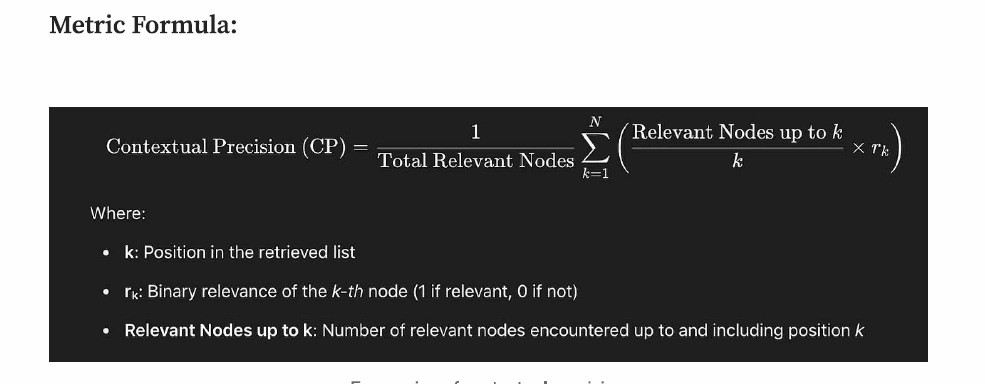

In [38]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [39]:
# Examples
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context


["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [40]:
human_answer = """AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robotics and autonomous vehicles."""

In [41]:
new_context = ["Machine Learning is the study of algorithms which learn with more data",
               "AI is known for Artificial Intelligence"] + retrieved_context
new_context

['Machine Learning is the study of algorithms which learn with more data',
 'AI is known for Artificial Intelligence',
 "Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels 

# Contexual Precision Metrics

In [42]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import ContextualPrecisionMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=new_context
)
test_case1 = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=retrieved_context
)


metrics = ContextualPrecisionMetric(
    threshold=0.50,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case1], [metrics])

✨ You're running DeepEval's latest Contextual Precision Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Contextual Precision Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdict": "yes",
        "reason": "The context states 'Artificial intelligence refers to machines mimicking human intelligence, 
like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous 
vehicles.' This directly aligns with the expected output."
    },
    {
        "verdict": "no",
        "reason": "The context focuses on 'NLP as a branch of AI' and its techniques, which is not directly 
relevant to the general definition of AI or its applications mentioned in the expected output."
    },
    {
        "verdict": "no",
        "reason": "The context discusses 'Machine learning as a field of artificial intelligence' and its 
applications, which is not directly relevant to the general definition of AI or its applications mentioned in the 
expected output."
    },
    {
        "verdict": "no",
        "reason": "The context is about 'Deep learning as a subset of machine learning' and its tasks, which is not
directly relevant to the general definition of AI or its applications mentioned in the expected output."
    }
]
 
Score: 1.0
Reason: The score is 1.00 because the first node in the retrieval contexts perfectly aligns with the input by 
stating 'Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and 
learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles.' This ensures that 
the relevant information is prioritized, while the subsequent nodes, which focus on specific branches like 'NLP as 
a branch of AI', 'Machine learning as a field of artificial intelligence', and 'Deep learning as a subset of 
machine learning', are correctly ranked lower as they do not directly address the general definition of AI.

======================================================================



Metrics Summary

  - ✅ Contextual Precision (score: 1.0, threshold: 0.5, strict: False, evaluation model: gpt-4o, reason: The score is 1.00 because the first node in the retrieval contexts perfectly aligns with the input by stating 'Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles.' This ensures that the relevant information is prioritized, while the subsequent nodes, which focus on specific branches like 'NLP as a branch of AI', 'Machine learning as a field of artificial intelligence', and 'Deep learning as a subset of machine learning', are correctly ranked lower as they do not directly address the general definition of AI., error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual as

⚠ WARNING: No hyperparameters logged.
» ]8;id=481112;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 10.26s | token cost: 0.006380000000000001 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [43]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 1.0
Reason The score is 1.00 because the first node in the retrieval contexts perfectly aligns with the input by stating 'Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles.' This ensures that the relevant information is prioritized, while the subsequent nodes, which focus on specific branches like 'NLP as a branch of AI', 'Machine learning as a field of artificial intelligence', and 'Deep learning as a subset of machine learning', are correctly ranked lower as they do not directly address the general definition of AI.


# Contextual Recall

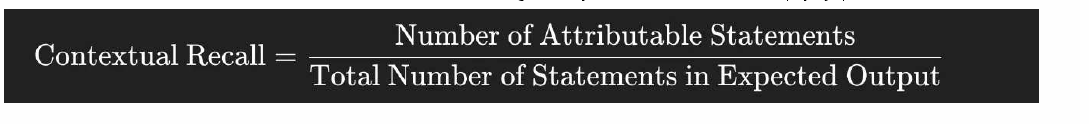

In [44]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [45]:
# Example 1

retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [46]:
human_answer = """AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robotics and autonomous vehicles."""

In [47]:
new_context = ['NVIDIA makes chips for AI', 'AI is an acronym for Artificial Intellengence.']
new_context

['NVIDIA makes chips for AI', 'AI is an acronym for Artificial Intellengence.']

In [48]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import ContextualRecallMetric
from deepeval import evaluate


test_case1 = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=retrieved_context
)

test_case2 = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=new_context
)


metrics = ContextualRecallMetric(
    threshold=0.60,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case1, test_case2], [metrics])

✨ You're running DeepEval's latest Contextual Recall Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Contextual Recall Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdict": "yes",
        "reason": "The sentence can be attributed to the 1st node in the retrieval context, which mentions 'AI 
includes applications like virtual assistants, robotics, and autonomous vehicles.'."
    }
]
 
Score: 1.0
Reason: The score is 1.00 because the expected output perfectly aligns with the information in the 1st node in the 
retrieval context, highlighting AI's applications in virtual assistants, robotics, and autonomous vehicles. Great 
job!

======================================================================

**************************************************

Contextual Recall Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdict": "yes",
        "reason": "The sentence can be attributed to the 2nd node in the retrieval context, which states 'AI is an 
acronym for Artificial Intellengence.' This aligns with the part 'AI, also known as Artificial Intelligence...' in 
the sentence."
    },
    {
        "verdict": "no",
        "reason": "The sentence mentions 'complex systems for applications like virtual assistants, robotics and 
autonomous vehicles,' which is not covered in the retrieval context. The context only mentions 'NVIDIA makes chips 
for AI' and does not elaborate on applications."
    }
]
 
Score: 0.5
Reason: The score is 0.50 because the retrieval context partially supports the expected output. The supportive 
reason is linked to the 2nd node in the retrieval context, which confirms the definition of AI. However, the 
unsupportive reason arises as the retrieval context lacks details on applications like virtual assistants, 
robotics, and autonomous vehicles, leading to a partial match.

======================================================================



Metrics Summary

  - ✅ Contextual Recall (score: 1.0, threshold: 0.6, strict: False, evaluation model: gpt-4o, reason: The score is 1.00 because the expected output perfectly aligns with the information in the 1st node in the retrieval context, highlighting AI's applications in virtual assistants, robotics, and autonomous vehicles. Great job!, error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robotics and autonomous vehicles.
  - context: None
  - retrieval context: ["Artificial intelligence refers to machines mimicking human intelligence, like p

⚠ WARNING: No hyperparameters logged.
» ]8;id=633994;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 4.99s | token cost: 0.007775000000000001 USD)
» Test Results (2 total tests):
   » Pass Rate: 50.0% | Passed: 1 | Failed: 1

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [49]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 1.0
Reason The score is 1.00 because the expected output perfectly aligns with the information in the 1st node in the retrieval context, highlighting AI's applications in virtual assistants, robotics, and autonomous vehicles. Great job!


In [50]:
print("Success", result.test_results[1].metrics_data[0].success)
print("Score", result.test_results[1].metrics_data[0].score)
print("Reason", result.test_results[1].metrics_data[0].reason)

Success False
Score 0.5
Reason The score is 0.50 because the retrieval context partially supports the expected output. The supportive reason is linked to the 2nd node in the retrieval context, which confirms the definition of AI. However, the unsupportive reason arises as the retrieval context lacks details on applications like virtual assistants, robotics, and autonomous vehicles, leading to a partial match.


# Contextual Relevancy

image.png

In [51]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [52]:
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [53]:
new_context = ['NVIDIA makes chips for betterment purpose','I do not know what is AI','Google and Microsoft are battling out the market share for AI Chatbots'] + retrieved_context
new_context

['NVIDIA makes chips for betterment purpose',
 'I do not know what is AI',
 'Google and Microsoft are battling out the market share for AI Chatbots',
 "Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networ

In [54]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import ContextualRelevancyMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=new_context
)

metrics = ContextualRelevancyMetric(
    threshold=0.80,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Contextual Relevancy Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Contextual Relevancy Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdicts": [
            {
                "statement": "NVIDIA makes chips for betterment purpose",
                "verdict": "no",
                "reason": "The statement 'NVIDIA makes chips for betterment purpose' does not relate to the 
question 'What is AI?' as it focuses on NVIDIA's activities rather than explaining AI."
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "I do not know what is AI",
                "verdict": "no",
                "reason": "The statement 'I do not know what is AI' does not provide any information about what AI 
is."
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "Google and Microsoft are battling out the market share for AI Chatbots",
                "verdict": "yes",
                "reason": null
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "Artificial intelligence refers to machines mimicking human intelligence, like 
problem-solving and learning.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "AI includes applications like virtual assistants, robotics, and autonomous 
vehicles.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "It's evolving rapidly with advancements in machine learning and deep learning.",
                "verdict": "yes",
                "reason": null
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "NLP is a branch of AI that enables computers to understand, interpret, and generate 
human language.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "Techniques include tokenization, stemming, and sentiment analysis.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "Applications range from chatbots to language translation services.",
                "verdict": "yes",
                "reason": null
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "Machine learning is a field of artificial intelligence focused on enabling systems to
learn patterns from data.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "Algorithms analyze past data to make predictions or classify information.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "Popular applications include recommendation systems and image recognition.",
                "verdict": "yes",
                "reason": null
            }
        ]
    },
    {
        "verdicts": [
            {
                "statement": "Deep learning is a subset of machine learning utilizing neural networks with many 
layers.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "It excels in complex tasks like image and speech recognition.",
                "verdict": "yes",
                "reason": null
            },
            {
                "statement": "Convolutional and recurrent neural networks are among the common architectures 
used.",
                "verdict": "yes",
                "reason": null
            }
        ]
    }
]
 
Score: 0.8666666666666667
Reason: The score is 0.87 because while some statements like 'Artificial intelligence refers to machines mimicking 
human intelligence' and 'AI includes applications like virtual assistants, robotics, and autonomous vehicles' are 
directly relevant to explaining AI, others like 'NVIDIA makes chips for betterment purpose' do not contribute to 
understanding w

======================================================================



Metrics Summary

  - ✅ Contextual Relevancy (score: 0.8666666666666667, threshold: 0.8, strict: False, evaluation model: gpt-4o, reason: The score is 0.87 because while some statements like 'Artificial intelligence refers to machines mimicking human intelligence' and 'AI includes applications like virtual assistants, robotics, and autonomous vehicles' are directly relevant to explaining AI, others like 'NVIDIA makes chips for betterment purpose' do not contribute to understanding what AI is., error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robo

⚠ WARNING: No hyperparameters logged.
» ]8;id=111478;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 5.26s | token cost: 0.016067500000000005 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [55]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 0.8666666666666667
Reason The score is 0.87 because while some statements like 'Artificial intelligence refers to machines mimicking human intelligence' and 'AI includes applications like virtual assistants, robotics, and autonomous vehicles' are directly relevant to explaining AI, others like 'NVIDIA makes chips for betterment purpose' do not contribute to understanding what AI is.


# Generator Evaluation Metrics

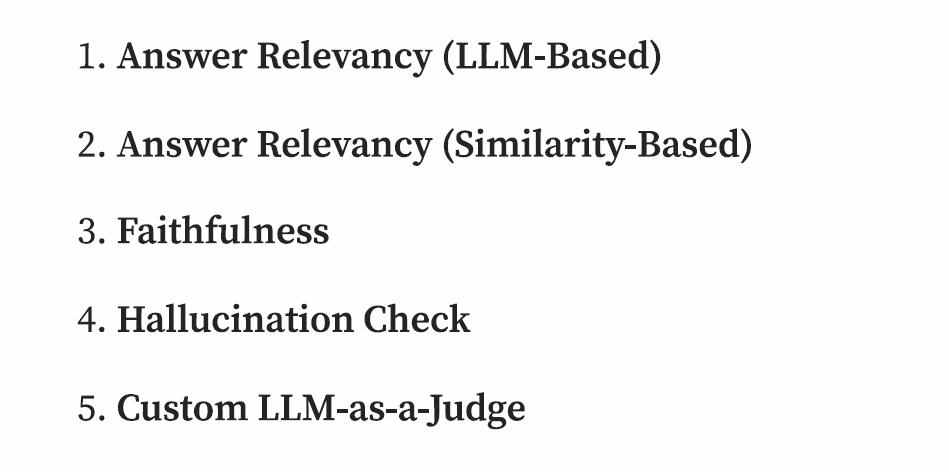

### LLM-Based Answer Relevancy - DeepEval

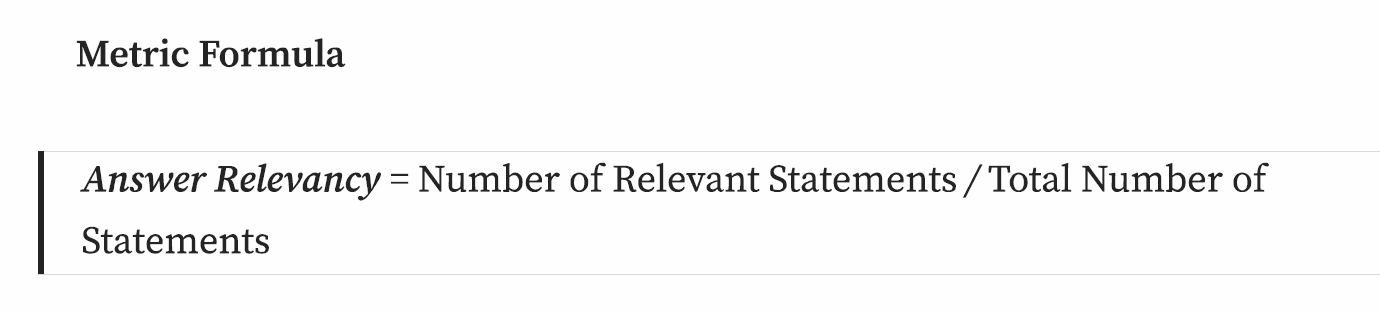

### Semantic Similarity based Answer Relevancy - RAGAS

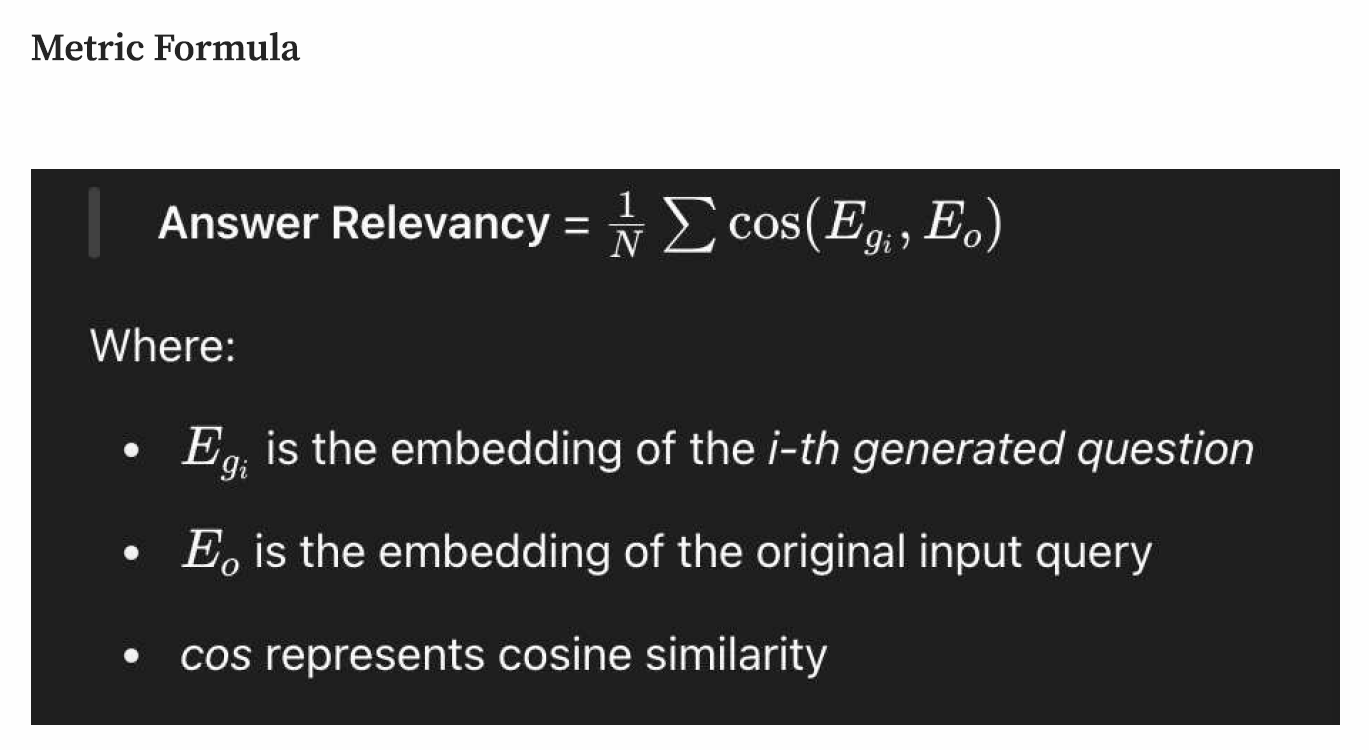

In [56]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

## Example - DeepEval

In [57]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import AnswerRelevancyMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    )

metrics = AnswerRelevancyMetric(
    threshold=0.50,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Answer Relevancy Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Answer Relevancy Verbose Logs

**************************************************

Statements:
[
    "Artificial intelligence refers to machines mimicking human intelligence.",
    "AI includes applications like virtual assistants, robotics, and autonomous vehicles.",
    "AI is evolving rapidly with advancements in machine learning and deep learning."
] 
 
Verdicts:
[
    {
        "verdict": "yes",
        "reason": null
    },
    {
        "verdict": "yes",
        "reason": null
    },
    {
        "verdict": "yes",
        "reason": null
    }
]
 
Score: 1.0
Reason: The score is 1.00 because the response perfectly addressed the question 'What is AI?' without any 
irrelevant statements. Great job on staying focused and providing a clear, concise answer!

======================================================================



Metrics Summary

  - ✅ Answer Relevancy (score: 1.0, threshold: 0.5, strict: False, evaluation model: gpt-4o, reason: The score is 1.00 because the response perfectly addressed the question 'What is AI?' without any irrelevant statements. Great job on staying focused and providing a clear, concise answer!, error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: None
  - context: None
  - retrieval context: None


Overall Metric Pass Rates

Answer Relevancy: 100.00% pass rate




⚠ WARNING: No hyperparameters logged.
» ]8;id=813713;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 3.57s | token cost: 0.0040175 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [58]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 1.0
Reason The score is 1.00 because the response perfectly addressed the question 'What is AI?' without any irrelevant statements. Great job on staying focused and providing a clear, concise answer!


# Example - RAGAS

In [59]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [60]:
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [61]:
human_answer = """AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robotics and autonomous vehicles."""

In [62]:
#!pip install ragas==0.3.7
#!pip install deepeval==3.6.8

In [63]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics.ragas import RAGASAnswerRelevancyMetric
from deepeval import evaluate
from langchain_openai import OpenAIEmbeddings

In [64]:
test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    retrieval_context= retrieved_context
        )

metrics = RAGASAnswerRelevancyMetric(
    threshold=0.50,
    model ="gpt-4o",
    embeddings=OpenAIEmbeddings()
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Answer Relevancy (ragas) Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

TypeError: capture_metric_type() missing 1 required positional argument: 'in_component'

# Faithfulness

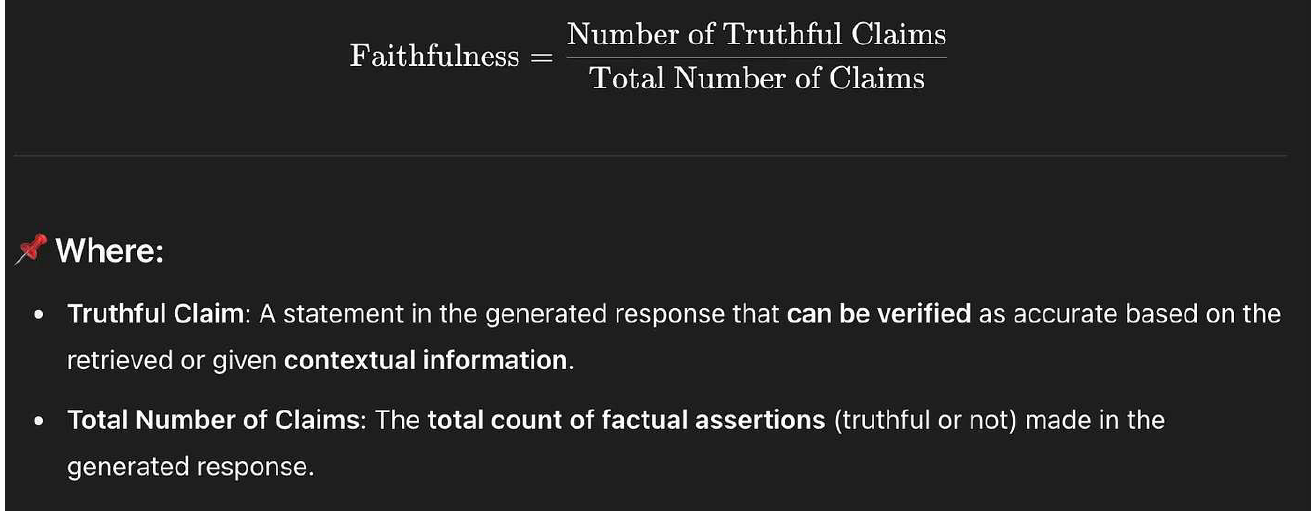

In [65]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [66]:
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [67]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import FaithfulnessMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    retrieval_context= retrieved_context
    )

metrics = FaithfulnessMetric(
    threshold=0.50,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Faithfulness Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Faithfulness Verbose Logs

**************************************************

Truths (limit=None):
[
    "Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning.",
    "AI includes applications like virtual assistants, robotics, and autonomous vehicles.",
    "AI is evolving rapidly with advancements in machine learning and deep learning.",
    "NLP is a branch of AI that enables computers to understand, interpret, and generate human language.",
    "NLP techniques include tokenization, stemming, and sentiment analysis.",
    "NLP applications range from chatbots to language translation services.",
    "Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from 
data.",
    "Machine learning algorithms analyze past data to make predictions or classify information.",
    "Popular applications of machine learning include recommendation systems and image recognition.",
    "Deep learning is a subset of machine learning utilizing neural networks with many layers.",
    "Deep learning excels in complex tasks like image and speech recognition.",
    "Convolutional and recurrent neural networks are among the common architectures used in deep learning."
] 
 
Claims:
[
    "Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning.",
    "AI includes applications like virtual assistants, robotics, and autonomous vehicles.",
    "AI is evolving rapidly with advancements in machine learning and deep learning."
] 
 
Verdicts:
[
    {
        "verdict": "yes",
        "reason": null
    },
    {
        "verdict": "yes",
        "reason": null
    },
    {
        "verdict": "yes",
        "reason": null
    }
]
 
Score: 1.0
Reason: The score is 1.00 because there are no contradictions between the actual output and the retrieval context. 
Everything aligns perfectly, showcasing a high level of accuracy and consistency. Great job!

======================================================================



Metrics Summary

  - ✅ Faithfulness (score: 1.0, threshold: 0.5, strict: False, evaluation model: gpt-4o, reason: The score is 1.00 because there are no contradictions between the actual output and the retrieval context. Everything aligns perfectly, showcasing a high level of accuracy and consistency. Great job!, error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: None
  - context: None
  - retrieval context: ["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning

⚠ WARNING: No hyperparameters logged.
» ]8;id=743819;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 4.33s | token cost: 0.0076275000000000015 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

# Hallucination Check

image.png

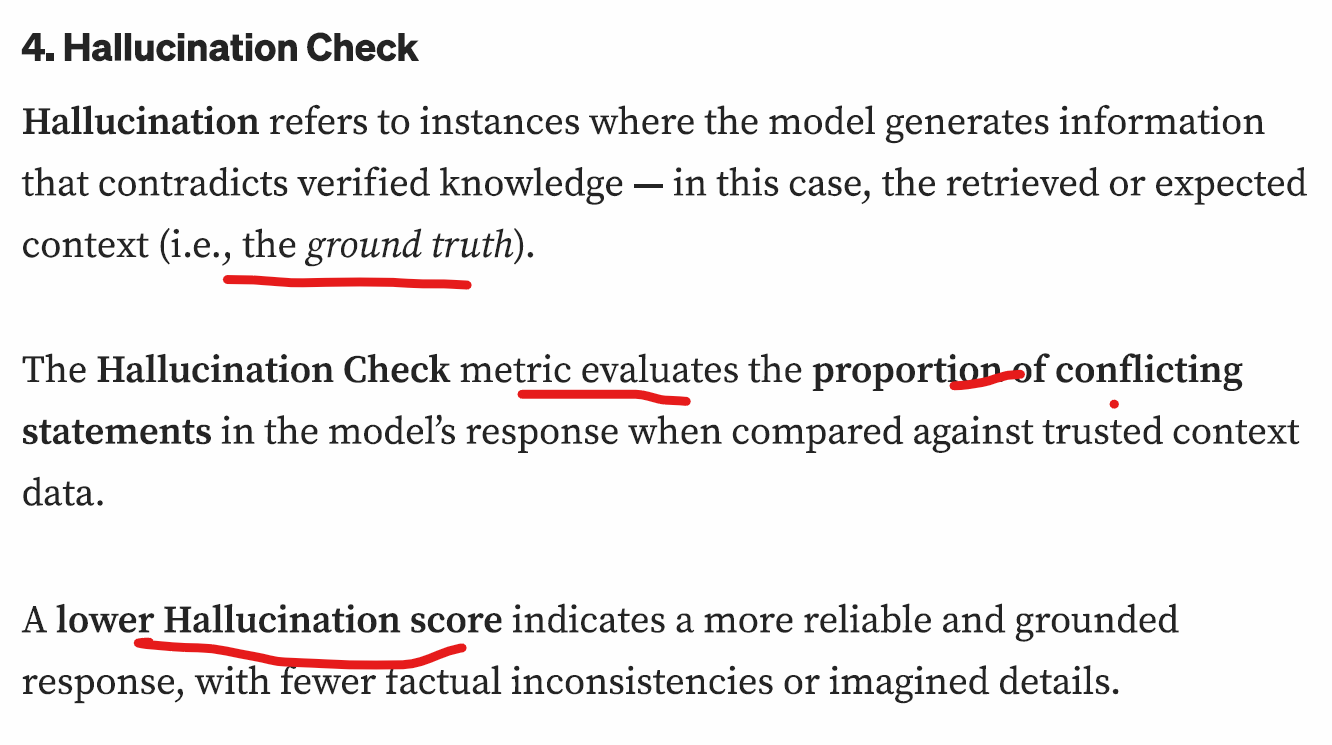

In [68]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [69]:
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [71]:
human_ground_truth_context = [""" "Artificial intelligence refers to machines mimicking human intelligence,
                  like problem-solving and learning. AI includes applications like virtual assistants,
                  robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning
                  and deep learning.", "Machine Learning  """]

In [72]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import HallucinationMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    context= human_ground_truth_context
    )

metrics = HallucinationMetric(
    threshold=0.10,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Hallucination Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Hallucination Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdict": "yes",
        "reason": "The actual output agrees with the provided context, as it accurately describes artificial 
intelligence and its applications, including virtual assistants, robotics, and autonomous vehicles, as well as its 
evolution with advancements in machine learning and deep learning."
    }
]
 
Score: 0.0
Reason: The score is 0.00 because the actual output perfectly aligns with the provided context, with no 
contradictions present, indicating complete factual accuracy.

======================================================================



Metrics Summary

  - ✅ Hallucination (score: 0.0, threshold: 0.1, strict: False, evaluation model: gpt-4o, reason: The score is 0.00 because the actual output perfectly aligns with the provided context, with no contradictions present, indicating complete factual accuracy., error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: None
  - context: [' "Artificial intelligence refers to machines mimicking human intelligence,\n                  like problem-solving and learning. AI includes applications like virtual assistants,\n                  robotics, and autonomous vehicles. It\'s evolving rapidly with advancements in machine learning\n                  and deep learning.", "Mach

⚠ WARNING: No hyperparameters logged.
» ]8;id=485613;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 3.57s | token cost: 0.0029775 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [73]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 0.0
Reason The score is 0.00 because the actual output perfectly aligns with the provided context, with no contradictions present, indicating complete factual accuracy.


In [74]:
# dummy examples
ai_response = 'AI refers to machines mimicking human intelligence to produce cyborgs and electric sheep'

In [75]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import HallucinationMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= ai_response,
    context= human_ground_truth_context
    )

metrics = HallucinationMetric(
    threshold=0.10,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Hallucination Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

**************************************************

Hallucination Verbose Logs

**************************************************

Verdicts:
[
    {
        "verdict": "no",
        "reason": "The actual output contradicts the context by stating that AI produces cyborgs and electric 
sheep, which is not mentioned in the context. Correction: AI refers to machines mimicking human intelligence, like 
problem-solving and learning, and includes applications like virtual assistants, robotics, and autonomous 
vehicles."
    }
]
 
Score: 1.0
Reason: The score is 1.00 because the actual output contains significant contradictions with the context, 
specifically by introducing concepts like cyborgs and electric sheep that are not supported by the provided 
context. This indicates a complete deviation from factual information, resulting in the highest possible 
hallucination score.

======================================================================



Metrics Summary

  - ❌ Hallucination (score: 1.0, threshold: 0.1, strict: False, evaluation model: gpt-4o, reason: The score is 1.00 because the actual output contains significant contradictions with the context, specifically by introducing concepts like cyborgs and electric sheep that are not supported by the provided context. This indicates a complete deviation from factual information, resulting in the highest possible hallucination score., error: None)

For test case:

  - input: What is AI?
  - actual output: AI refers to machines mimicking human intelligence to produce cyborgs and electric sheep
  - expected output: None
  - context: [' "Artificial intelligence refers to machines mimicking human intelligence,\n                  like problem-solving and learning. AI includes applications like virtual assistants,\n                  robotics, and autonomous vehicles. It\'s evolving rapidly with advancements in machine learning\n                  and deep learning.", "Machine Learn

⚠ WARNING: No hyperparameters logged.
» ]8;id=471694;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 4.41s | token cost: 0.0033725 USD)
» Test Results (1 total tests):
   » Pass Rate: 0.0% | Passed: 0 | Failed: 1

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [76]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success False
Score 1.0
Reason The score is 1.00 because the actual output contains significant contradictions with the context, specifically by introducing concepts like cyborgs and electric sheep that are not supported by the provided context. This indicates a complete deviation from factual information, resulting in the highest possible hallucination score.


# Customer LLM as a judge (G-Eval) - COT to evaluate LLM outputs based on ANY custom criteria.

In [77]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [78]:
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context

["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common ar

In [79]:
ai_response = response['response']
ai_response

"Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."

In [80]:
human_answer = """AI, also known as Artificial Intelligence is used to build complex systems for applications like
                virtual assistants, robotics, and autonomous vehicles."""
human_answer

'AI, also known as Artificial Intelligence is used to build complex systems for applications like \n                virtual assistants, robotics, and autonomous vehicles.'

In [82]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import GEval
from deepeval import evaluate
from deepeval.test_case import LLMTestCaseParams


test_case = LLMTestCase(
    input = response['question'],
    actual_output= ai_response,
    expected_output=human_answer,
    retrieval_context= retrieved_context
    )

metric = GEval(
    threshold=0.5, model="gpt-4o",name="RAG Fact Checker",
    # Note: You can only provide either criteria or evaluation_steps, and not both
    evaluation_steps= [
        "Create a list of statements from 'actual output'",
        "Validate if they are relevant and answers the given question in 'input', penalize if any statements are irrelevant",
        "Also validate if they exist in 'expected output', penalize if any statements are missing or factually wrong. ",
        "Also validate if these statements are grounded in the 'retrieval context' and penalize if they are missing or factually incorrect",
        "Finally also penalize if any statements seem to be invented or made up and do not make sense factually given the 'input' and 'retrieval context'"
    ],
    evaluation_params=[LLMTestCaseParams.INPUT,
                       LLMTestCaseParams.ACTUAL_OUTPUT,
                       LLMTestCaseParams.EXPECTED_OUTPUT,
                       LLMTestCaseParams.RETRIEVAL_CONTEXT],
    verbose_mode=True)
result = evaluate([test_case],[metric])






✨ You're running DeepEval's latest RAG Fact Checker [GEval] Metric! (using gpt-4o, strict=False, 
async_mode=True)...

Output()

**************************************************

RAG Fact Checker [GEval] Verbose Logs

**************************************************

Criteria:
None 
 
Evaluation Steps:
[
    "Create a list of statements from 'actual output'",
    "Validate if they are relevant and answers the given question in 'input', penalize if any statements are 
irrelevant",
    "Also validate if they exist in 'expected output', penalize if any statements are missing or factually wrong. 
",
    "Also validate if these statements are grounded in the 'retrieval context' and penalize if they are missing or 
factually incorrect",
    "Finally also penalize if any statements seem to be invented or made up and do not make sense factually given 
the 'input' and 'retrieval context'"
] 
 
Rubric:
None 
 
Score: 0.886785020621476
 
Reason: The actual output is highly aligned with the evaluation steps. It accurately defines AI as machines 
mimicking human intelligence, which is relevant to the input question. The statements about AI applications like 
virtual assistants, robotics, and autonomous vehicles are present in both the expected output and the retrieval 
context, ensuring factual correctness. The mention of AI evolving with advancements in machine learning and deep 
learning is also grounded in the retrieval context. There are no irrelevant or invented statements, but the 
definition of AI as 'Artificial Intelligence' is missing, which slightly affects completeness.

======================================================================



Metrics Summary

  - ✅ RAG Fact Checker [GEval] (score: 0.886785020621476, threshold: 0.5, strict: False, evaluation model: gpt-4o, reason: The actual output is highly aligned with the evaluation steps. It accurately defines AI as machines mimicking human intelligence, which is relevant to the input question. The statements about AI applications like virtual assistants, robotics, and autonomous vehicles are present in both the expected output and the retrieval context, ensuring factual correctness. The mention of AI evolving with advancements in machine learning and deep learning is also grounded in the retrieval context. There are no irrelevant or invented statements, but the definition of AI as 'Artificial Intelligence' is missing, which slightly affects completeness., error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtua

⚠ WARNING: No hyperparameters logged.
» ]8;id=79717;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 2.74s | token cost: 0.0027625 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [83]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 0.886785020621476
Reason The actual output is highly aligned with the evaluation steps. It accurately defines AI as machines mimicking human intelligence, which is relevant to the input question. The statements about AI applications like virtual assistants, robotics, and autonomous vehicles are present in both the expected output and the retrieval context, ensuring factual correctness. The mention of AI evolving with advancements in machine learning and deep learning is also grounded in the retrieval context. There are no irrelevant or invented statements, but the definition of AI as 'Artificial Intelligence' is missing, which slightly affects completeness.
